# Event rate oscillogram, angular smearing, and uncertainty budget

Standalone companion to `evt_rate_calc.ipynb`. Reproduces the flux / cross-section / angular-resolution / oscillation pipeline from that notebook, then adds:

- an **event-rate oscillogram** ($\cos\theta$ vs $E_\nu$, colored by event rate instead of probability)
- an **angular-smeared rate** spectrum, showing the effect of the $\cos\theta$ uncertainty implied by the angular resolution
- the **relative total uncertainty** $\sigma_N / N$ vs energy

## 1. Atmospheric neutrino flux

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as interp
from scipy.interpolate import RegularGridInterpolator
from scipy.integrate import simpson
from scipy.ndimage import gaussian_filter1d
import uproot

with open('hms-nu-20-01-000.d') as f:
    with open('hms-nu-20-01-n3650.d') as l:
        lines_min = (line for line in f if 'average' not in line and 'Enu' not in line)
        lines_max = (line for line in l if 'average' not in line and 'Enu' not in line)
        all_flux_data_min = np.loadtxt(lines_min)
        all_flux_data_max = np.loadtxt(lines_max)

        flux_data_numu = (all_flux_data_min[:, [0, 1]] + all_flux_data_max[:, [0, 1]]) / 2
        numu_uncertainty = np.abs(all_flux_data_min[:, [0, 1]] - all_flux_data_max[:, [0, 1]]) / 2


In [2]:
n_energy = 101
energies = all_flux_data_min[:n_energy, 0]
num_cos = len(all_flux_data_min) // n_energy
cos_bins_centers = np.linspace(-0.95, 0.95, num_cos)


def make_interpolator(data):
    """Create a 2D flux interpolator from [energy, value] blocks."""
    values = data[:, 1].reshape(num_cos, n_energy)
    return RegularGridInterpolator(
        (cos_bins_centers, energies),
        values,
        method="linear",
        bounds_error=False,
        fill_value=0,
    )


flux_interpolator = make_interpolator(flux_data_numu)
uncertainty_interpolator = make_interpolator(numu_uncertainty)


def get_flux(cos_theta, energy, uncertainty=False):
    """Return interpolated nu_mu flux or its uncertainty."""
    interpolator = uncertainty_interpolator if uncertainty else flux_interpolator
    points = np.column_stack([np.atleast_1d(cos_theta), np.atleast_1d(energy)])
    return interpolator(points)


print(f"nu_mu flux at cos=-0.12, E=1.5 GeV: {get_flux(-0.12, 1.5)[0]:.2e}")


nu_mu flux at cos=-0.12, E=1.5 GeV: 7.10e+01


## 2. Cross section (GENIE)

In [3]:
energy_bins = np.linspace(0.5, 8.0, 62)
energy_bins_centers = (energy_bins[:-1] + energy_bins[1:]) / 2
energy_bins_edges = energy_bins

# Load the ROOT cross-section graph.
file = uproot.open("/Users/taozhou/Downloads/genie_xsec/v3_06_00/NULL/AR2320i00000-k250-e1000/data/xsec_graphs.root")
graph = file["nu_mu_Ar40"]["tot_cc;1"]
x_values = np.asarray(graph.member("fX"))
y_values = np.asarray(graph.member("fY"))

inter_xy = interp.interp1d(
    x_values,
    y_values,
    bounds_error=False,
    fill_value=0,
)
xsec = inter_xy(energy_bins_centers)

# Convert cross section from 10^-38 cm^2 to m^2 and scale by argon count (20 kt FD).
conv = 1e-38 * 1e-4
noar = 20 * 1e3 * 1e6 * 6.022e23 / 39.948
scaled_xsec = conv * noar * xsec


## 3. Angular resolution

In [4]:
x_ang, y_ang = np.loadtxt("angular_resolution.txt", delimiter=",", skiprows=1, unpack=True)
inter_xy_ang = interp.interp1d(
    x_ang,
    y_ang,
    kind="linear",
    bounds_error=False,
    fill_value=0,
)
angular_res = inter_xy_ang(energy_bins_centers)  # degrees, per energy bin


## 4. Oscillation probability

In [5]:
r = 6371  # earth radius in km
d = 20    # average altitude of neutrino production in the atmosphere in km
s = 1.5   # depth of DUNE FD in km


def zenith_to_baseline(x):
    """Convert zenith angle (cosine) to baseline length in km."""
    sqrt = np.sqrt(4 * x**2 * (s - r)**2 - 4 * (s**2 - 2 * r * s - d**2 - 2 * r * d))
    L = 1 / 2 * (-2 * x * (r - s) + sqrt)
    return L


In [6]:
from oscillation_tools import ThreeFlavorOscillation

osc_model_vac = ThreeFlavorOscillation(rho=0, channel="mu_mu")
osc_model = ThreeFlavorOscillation(channel="mu_mu")


## 5. Event rate (baseline calculation)

Same combined stat + flux + angular-resolution uncertainty budget as `evt_rate_calc.ipynb`.

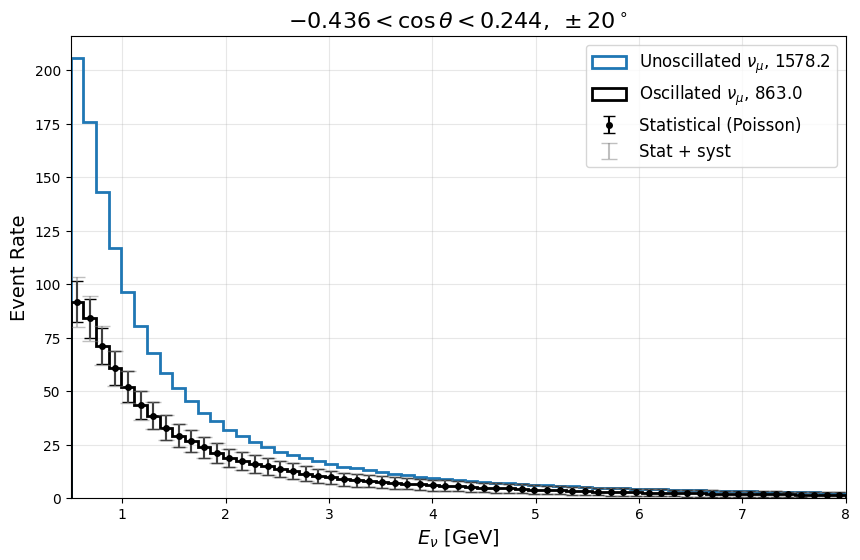

Total events (oscillated): 863.04
Total events (unoscillated): 1578.17
Total uncertainty: 196.84


In [7]:
delta_theta = 20


def cos_lim(delta_theta):
    theta_0 = 95.85  # zenith angle in degrees for the DUNE FD
    return (np.cos(np.radians(theta_0 + delta_theta)), np.cos(np.radians(theta_0 - delta_theta)))


cos_limit = cos_lim(delta_theta)
cos_grid = np.linspace(cos_limit[0], cos_limit[1], 100)

event_rate = np.zeros(len(energy_bins_centers))
event_rate_unosc = np.zeros(len(energy_bins_centers))
event_rate_uncertainty = np.zeros(len(energy_bins_centers))  # combined uncertainty
event_rate_stat = np.zeros(len(energy_bins_centers))
event_rate_syst = np.zeros(len(energy_bins_centers))

time_factor = 3 * 365.25 * 24 * 3600  # 3 years in seconds
energy_bin_width = energy_bins[1] - energy_bins[0]

for i, E in enumerate(energy_bins_centers):
    flux_values = np.array([get_flux(cos, E)[0] for cos in cos_grid])
    flux_uncertainty = np.array([get_flux(cos, E, uncertainty=True)[0] for cos in cos_grid])

    osc_prob = np.array([osc_model(L_km=zenith_to_baseline(cos), E_GeV=E) for cos in cos_grid])

    ang_res_deg = angular_res[i]
    ang_res_rad = np.radians(ang_res_deg)

    osc_prob_upper = np.zeros_like(cos_grid)
    osc_prob_lower = np.zeros_like(cos_grid)
    for j, cos in enumerate(cos_grid):
        baseline = zenith_to_baseline(cos)
        baseline_unc = 50 * ang_res_rad  # rough estimate: ~50 km per radian of uncertainty
        osc_prob_upper[j] = osc_model(L_km=baseline + baseline_unc, E_GeV=E)
        osc_prob_lower[j] = osc_model(L_km=baseline - baseline_unc, E_GeV=E)

    integrand_osc = flux_values * osc_prob * scaled_xsec[i] * 2 * np.pi * time_factor * energy_bin_width
    integrand_unosc = flux_values * scaled_xsec[i] * 2 * np.pi * time_factor * energy_bin_width

    integrand_osc_flux_upper = (flux_values + flux_uncertainty) * osc_prob * scaled_xsec[i] * 2 * np.pi * time_factor * energy_bin_width
    integrand_osc_flux_lower = (flux_values - flux_uncertainty) * osc_prob * scaled_xsec[i] * 2 * np.pi * time_factor * energy_bin_width

    integrand_osc_ang_upper = flux_values * osc_prob_upper * scaled_xsec[i] * 2 * np.pi * time_factor * energy_bin_width
    integrand_osc_ang_lower = flux_values * osc_prob_lower * scaled_xsec[i] * 2 * np.pi * time_factor * energy_bin_width

    event_rate[i] = simpson(integrand_osc, x=cos_grid)
    event_rate_unosc[i] = simpson(integrand_unosc, x=cos_grid)

    rate_flux_upper = simpson(integrand_osc_flux_upper, x=cos_grid)
    rate_flux_lower = simpson(integrand_osc_flux_lower, x=cos_grid)
    rate_ang_upper = simpson(integrand_osc_ang_upper, x=cos_grid)
    rate_ang_lower = simpson(integrand_osc_ang_lower, x=cos_grid)

    sigma_flux = 0.5 * (abs(rate_flux_upper - event_rate[i]) + abs(event_rate[i] - rate_flux_lower))
    sigma_ang = 0.5 * (abs(rate_ang_upper - event_rate[i]) + abs(event_rate[i] - rate_ang_lower))
    sigma_stat = np.sqrt(max(event_rate[i], 0.0))

    event_rate_stat[i] = sigma_stat
    event_rate_syst[i] = np.sqrt(sigma_flux**2 + sigma_ang**2)
    event_rate_uncertainty[i] = np.sqrt(sigma_stat**2 + sigma_flux**2 + sigma_ang**2)

plt.figure(figsize=(10, 6))
plt.hist(energy_bins_centers, weights=event_rate_unosc, bins=energy_bins_edges, histtype="step",
         label=rf'Unoscillated $\nu_\mu$, ${np.sum(event_rate_unosc):.1f}$', linewidth=2)
plt.hist(energy_bins_centers, weights=event_rate, bins=energy_bins_edges, histtype="step",
         label=rf'Oscillated $\nu_\mu$, ${np.sum(event_rate):.1f}$', linewidth=2, color='black')
plt.errorbar(energy_bins_centers, event_rate, yerr=event_rate_stat,
             fmt='o', color='black', markersize=4, capsize=4, label='Statistical (Poisson)')
plt.errorbar(energy_bins_centers, event_rate, yerr=event_rate_uncertainty,
             fmt='none', ecolor='gray', alpha=0.5, capsize=6, label='Stat + syst')
plt.xlabel(r"$E_{\nu}$ [GeV]", fontsize=14)
plt.ylabel("Event Rate", fontsize=14)
plt.xlim(0.5, 8)
plt.legend(fontsize=12)
plt.title(rf"${cos_limit[0]:.3f} < \cos\theta < {cos_limit[1]:.3f},\; \pm {delta_theta}^\circ$", fontsize=16)
plt.grid(True, alpha=0.3)
plt.show()

print(f"Total events (oscillated): {np.sum(event_rate):.2f}")
print(f"Total events (unoscillated): {np.sum(event_rate_unosc):.2f}")
print(f"Total uncertainty: {np.sum(event_rate_uncertainty):.2f}")


## 6. Event-rate oscillogram

Same $(\cos\theta, E)$ grid as the usual $P_{\mu\mu}$ oscillogram, but colored by the differential event rate ($\mathrm{flux}\times P_{\mu\mu}\times\sigma\times 2\pi\times t\times\Delta E$) instead of raw probability.

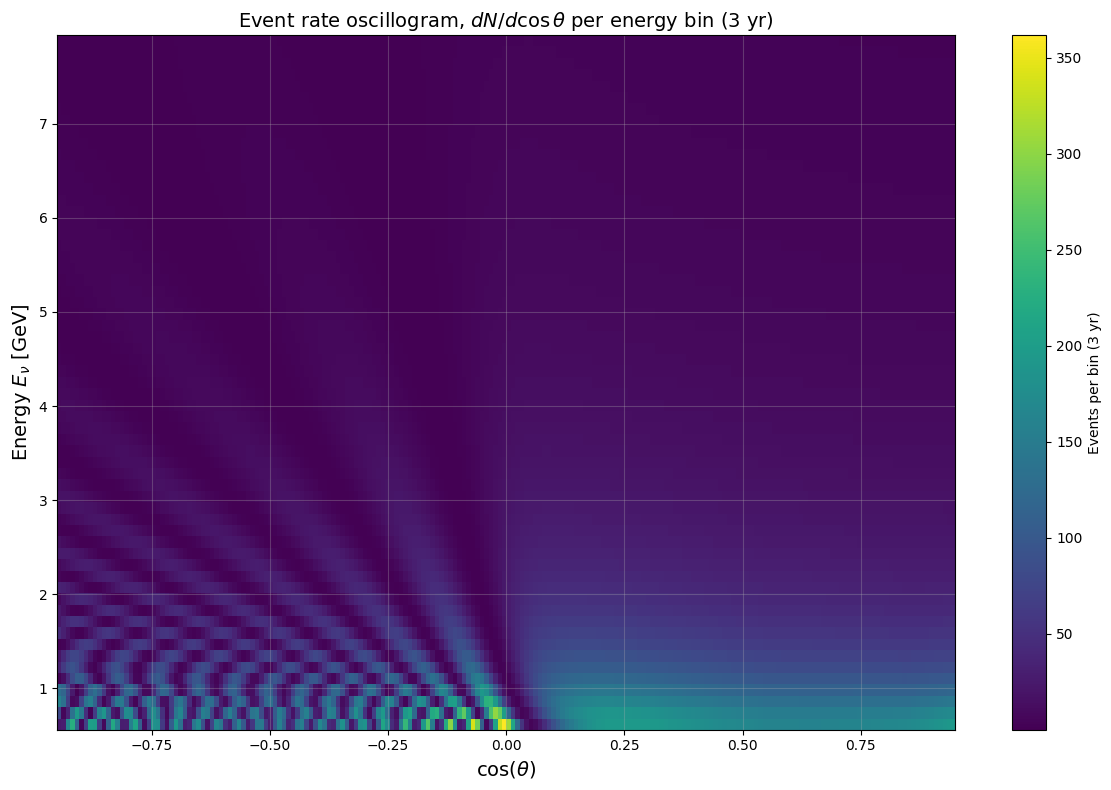

Event rate density range: 0.000238 to 362


In [8]:
zenith_angles_rate = np.linspace(-0.95, 0.95, 200)
rate_grid = np.zeros((len(energy_bins_centers), len(zenith_angles_rate)))

for i, E in enumerate(energy_bins_centers):
    flux_values = np.array([get_flux(cos, E)[0] for cos in zenith_angles_rate])
    osc_prob = np.array([osc_model(L_km=zenith_to_baseline(cos), E_GeV=E) for cos in zenith_angles_rate])
    rate_grid[i, :] = flux_values * osc_prob * scaled_xsec[i] * 2 * np.pi * time_factor * energy_bin_width

plt.figure(figsize=(12, 8))
im = plt.imshow(rate_grid, aspect='auto', origin='lower',
                extent=[zenith_angles_rate[0], zenith_angles_rate[-1],
                        energy_bins_centers[0], energy_bins_centers[-1]],
                cmap='viridis', interpolation='nearest')
plt.xlabel(r'$\cos(\theta)$', fontsize=14)
plt.ylabel(r'Energy $E_\nu$ [GeV]', fontsize=14)
plt.title(r'Event rate oscillogram, $dN/d\cos\theta$ per energy bin (3 yr)', fontsize=14)
cbar = plt.colorbar(im, label='Events per bin (3 yr)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('event_rate_oscillogram.pdf', dpi=300)
plt.show()

print(f"Event rate density range: {rate_grid.min():.3g} to {rate_grid.max():.3g}")


## 7. Angular-smeared rate

Blur the oscillogram along $\cos\theta$ with a Gaussian whose width comes from the (energy-dependent) angular resolution, evaluated at the DUNE FD zenith angle ($\theta_0 = 95.85^\circ$), then re-integrate over the FD acceptance window used above. This is the same $\cos\theta \leftrightarrow$ angular-resolution mapping used for the baseline-perturbation uncertainty in Section 5, applied directly to the 2D rate map instead of as an upper/lower envelope.

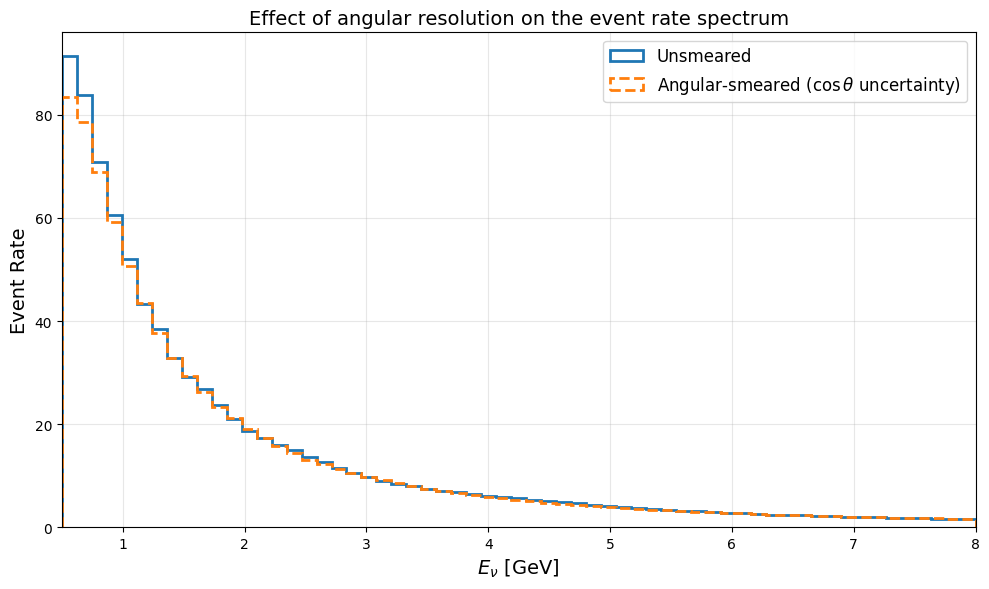

Total events -- unsmeared: 859.4, smeared: 835.3


In [9]:
theta0_deg = 95.85
dcos = zenith_angles_rate[1] - zenith_angles_rate[0]
sigma_cos = np.abs(np.sin(np.radians(theta0_deg))) * np.radians(angular_res)  # per energy bin, in cos(theta) units

rate_grid_smeared = np.zeros_like(rate_grid)
for i in range(len(energy_bins_centers)):
    sigma_pixels = max(sigma_cos[i] / dcos, 1e-6)
    rate_grid_smeared[i, :] = gaussian_filter1d(rate_grid[i, :], sigma=sigma_pixels, mode='constant')

window_mask = (zenith_angles_rate >= cos_limit[0]) & (zenith_angles_rate <= cos_limit[1])
event_rate_unsmeared = simpson(rate_grid[:, window_mask], x=zenith_angles_rate[window_mask], axis=1)
event_rate_smeared = simpson(rate_grid_smeared[:, window_mask], x=zenith_angles_rate[window_mask], axis=1)

plt.figure(figsize=(10, 6))
plt.hist(energy_bins_centers, weights=event_rate_unsmeared, bins=energy_bins_edges, histtype='step',
         label='Unsmeared', linewidth=2)
plt.hist(energy_bins_centers, weights=event_rate_smeared, bins=energy_bins_edges, histtype='step',
         label=r'Angular-smeared ($\cos\theta$ uncertainty)', linewidth=2, linestyle='dashed')
plt.xlabel(r"$E_{\nu}$ [GeV]", fontsize=14)
plt.ylabel("Event Rate", fontsize=14)
plt.xlim(0.5, 8)
plt.legend(fontsize=12)
plt.title('Effect of angular resolution on the event rate spectrum', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('event_rate_angular_smeared.pdf', dpi=300)
plt.show()

print(f"Total events -- unsmeared: {event_rate_unsmeared.sum():.1f}, smeared: {event_rate_smeared.sum():.1f}")


## 8. Relative total uncertainty $\sigma_N / N$

Uses the combined statistical + flux + angular-resolution uncertainty from Section 5.

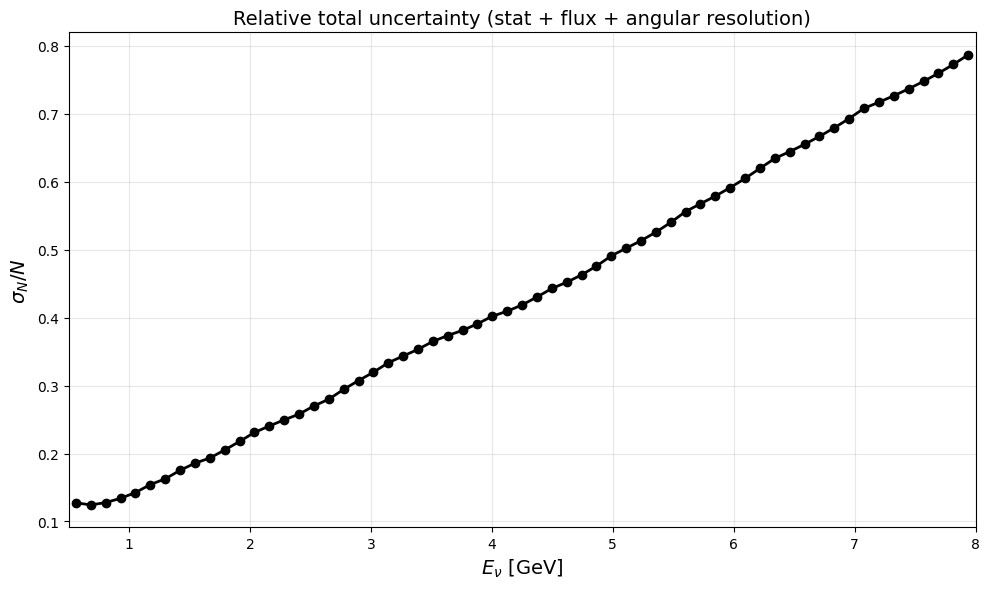

Relative uncertainty range: 0.124 to 0.787


In [10]:
relative_uncertainty = np.divide(
    event_rate_uncertainty, event_rate,
    out=np.full_like(event_rate_uncertainty, np.nan), where=event_rate > 0,
)

plt.figure(figsize=(10, 6))
plt.plot(energy_bins_centers, relative_uncertainty, marker='o', linewidth=2, color='black')
plt.xlabel(r"$E_{\nu}$ [GeV]", fontsize=14)
plt.ylabel(r"$\sigma_N / N$", fontsize=14)
plt.xlim(0.5, 8)
plt.grid(True, alpha=0.3)
plt.title('Relative total uncertainty (stat + flux + angular resolution)', fontsize=14)
plt.tight_layout()
plt.savefig('relative_uncertainty.pdf', dpi=300)
plt.show()

print(f"Relative uncertainty range: {np.nanmin(relative_uncertainty):.3f} to {np.nanmax(relative_uncertainty):.3f}")
